<a href="https://colab.research.google.com/github/Pablo09Ramos/Pablo09Ramos/blob/main/AprendizajeAutomatico1Act5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Pacientes: 768 | Prevalencia: 34.9%
AUC:   0.860
Brier: 0.149


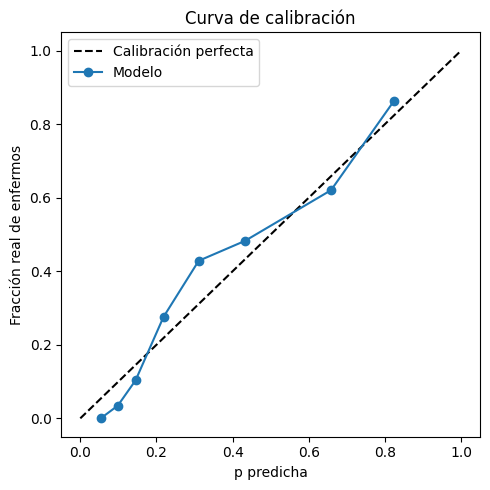


Umbral a1 -> a2: p = 0.0255
Umbral a2 -> a3: p = 0.4805

Tabla comparativa de decisiones:

        Paciente  Glucosa  IMC  Edad     p   R(a1)  R(a2)  R(a3)          Decisión óptima
 A (riesgo bajo)     87.0 21.8    21 0.050  2514.8 1393.9 3050.3 a2: Prueba confirmatoria
B (riesgo medio)    117.0 34.5    40 0.251 12537.6 2366.1 3250.8 a2: Prueba confirmatoria
 C (riesgo alto)    194.0 23.5    59 0.747 37336.9 4771.7 3746.7          a3: Tratamiento

Comparación de reglas de decisión:

                  Regla  Pérdida media por paciente (MXN)
Regla de Bayes (óptima)                            2618.0
    Siempre prueba (a2)                            2851.0
    Siempre tratar (a3)                            3351.0
     Umbral clásico 0.5                            9190.0
  Nunca intervenir (a1)                           17532.0

Decisiones de la regla de Bayes en el conjunto de prueba:

a2: Prueba confirmatoria    169
a3: Tratamiento              61
a1: No intervenir             1


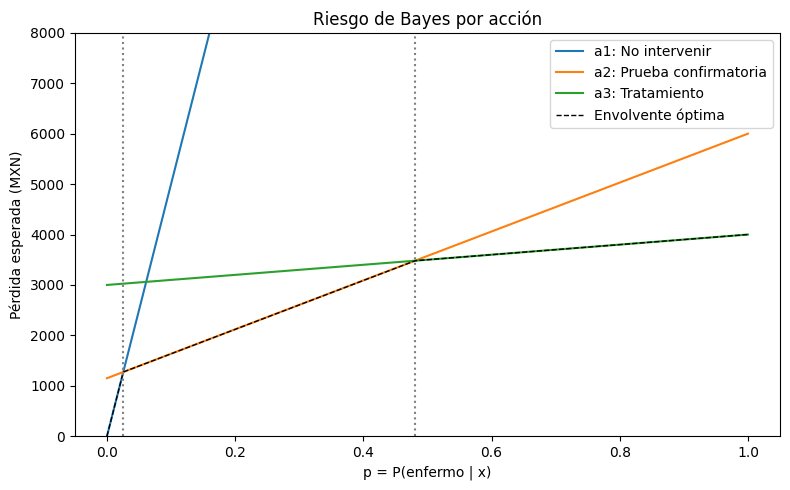


Sensibilidad al costo del falso negativo:

 Factor costo FN  Umbral a1->a2  Umbral a2->a3  Pérdida media (MXN)
             0.7         0.0381         0.4805                 2608
             1.0         0.0255         0.4805                 2618
             1.3         0.0191         0.4805                 2623


In [4]:
# =========================================================
# Actividad 5: Análisis de decisiones con modelos predictivos
# Caso: tamizaje de diabetes tipo 2 (dataset Pima, OpenML)
# pip install numpy pandas matplotlib scikit-learn
# =========================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, brier_score_loss

# ---------------------------------------------------------
# 1. Datos reales: Pima Indians Diabetes (requiere internet)
#    Variables: preg, plas (glucosa), pres (presión), skin,
#    insu (insulina), mass (IMC), pedi (antecedentes), age
# ---------------------------------------------------------
datos = fetch_openml("diabetes", version=1, as_frame=True)
X = datos.data.copy()
y = (datos.target == "tested_positive").astype(int).to_numpy()  # 1 = enfermo

# En este dataset los ceros en estas columnas son valores faltantes
cols_cero = ["plas", "pres", "skin", "insu", "mass"]
X[cols_cero] = X[cols_cero].replace(0, np.nan)

print(f"Pacientes: {len(X)} | Prevalencia: {y.mean():.1%}")

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y
)

# ---------------------------------------------------------
# 2. Modelo ML calibrado -> p = P(enfermo | x)
#    Imputación + estandarización + regresión logística,
#    y calibración de probabilidades (sigmoide, estable con
#    pocos datos; con >1000 casos se puede usar "isotonic")
# ---------------------------------------------------------
base = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)
modelo = CalibratedClassifierCV(base, method="sigmoid", cv=5)
modelo.fit(X_tr, y_tr)
p_te = modelo.predict_proba(X_te)[:, 1]

print(f"AUC:   {roc_auc_score(y_te, p_te):.3f}")
print(f"Brier: {brier_score_loss(y_te, p_te):.3f}")

# Curva de calibración
frac_pos, p_media = calibration_curve(y_te, p_te, n_bins=8, strategy="quantile")
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
plt.plot(p_media, frac_pos, "o-", label="Modelo")
plt.xlabel("p predicha")
plt.ylabel("Fracción real de enfermos")
plt.title("Curva de calibración")
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Función de pérdida L(a, theta) en MXN (supuestos ilustrativos)
#    filas = acciones, columnas = [enfermo, sano]
# ---------------------------------------------------------
acciones = ["a1: No intervenir", "a2: Prueba confirmatoria", "a3: Tratamiento"]
L = np.array([
    [50_000,     0],
    [ 6_000, 1_150],
    [ 4_000, 3_000],
], dtype=float)

def riesgo_bayes(p, L):
    """R(a|x) = p*L(a,enfermo) + (1-p)*L(a,sano). Devuelve matriz (n, acciones)."""
    p = np.atleast_1d(p)[:, None]
    return p * L[:, 0] + (1 - p) * L[:, 1]

def decision_optima(p, L):
    return np.argmin(riesgo_bayes(p, L), axis=1)

# ---------------------------------------------------------
# 4. Umbrales (intersección de rectas de riesgo)
# ---------------------------------------------------------
def umbral(i, j, L):
    return (L[j, 1] - L[i, 1]) / ((L[i, 0] - L[i, 1]) - (L[j, 0] - L[j, 1]))

t12 = umbral(0, 1, L)
t23 = umbral(1, 2, L)
print(f"\nUmbral a1 -> a2: p = {t12:.4f}")
print(f"Umbral a2 -> a3: p = {t23:.4f}")

# ---------------------------------------------------------
# 5. Tabla comparativa con pacientes reales del conjunto de prueba
#    (se eligen los más cercanos a p = 0.05, 0.25 y 0.75)
# ---------------------------------------------------------
objetivos = {"A (riesgo bajo)": 0.05, "B (riesgo medio)": 0.25, "C (riesgo alto)": 0.75}
idx = [np.abs(p_te - t).argmin() for t in objetivos.values()]

pacientes = pd.DataFrame({
    "Paciente": list(objetivos.keys()),
    "Glucosa": X_te["plas"].iloc[idx].values,
    "IMC": X_te["mass"].iloc[idx].values.round(1),
    "Edad": X_te["age"].iloc[idx].values,
    "p": p_te[idx].round(3),
})
R = riesgo_bayes(p_te[idx], L)
for k, nombre in enumerate(acciones):
    pacientes[f"R({nombre.split(':')[0]})"] = R[:, k].round(1)
pacientes["Decisión óptima"] = [acciones[i] for i in R.argmin(axis=1)]

print("\nTabla comparativa de decisiones:\n")
print(pacientes.to_string(index=False))

# ---------------------------------------------------------
# 6. Pérdida esperada: regla de Bayes vs. umbral clásico 0.5
#    y vs. estrategias fijas
# ---------------------------------------------------------
def perdida_media(decisiones, y_true, L):
    theta = 1 - y_true  # 0 = enfermo, 1 = sano
    return L[decisiones, theta].mean()

n_te = len(y_te)
reglas = {
    "Regla de Bayes (óptima)":      decision_optima(p_te, L),
    "Umbral clásico 0.5":           np.where(p_te >= 0.5, 2, 0),
    "Nunca intervenir (a1)":        np.zeros(n_te, dtype=int),
    "Siempre prueba (a2)":          np.ones(n_te, dtype=int),
    "Siempre tratar (a3)":          np.full(n_te, 2, dtype=int),
}
comparacion = pd.DataFrame({
    "Regla": list(reglas.keys()),
    "Pérdida media por paciente (MXN)": [
        perdida_media(d, y_te, L) for d in reglas.values()
    ],
}).sort_values("Pérdida media por paciente (MXN)").round(0)

print("\nComparación de reglas de decisión:\n")
print(comparacion.to_string(index=False))

# Distribución de decisiones de la regla de Bayes
conteo = pd.Series(reglas["Regla de Bayes (óptima)"]).map(
    dict(enumerate(acciones))
).value_counts()
print("\nDecisiones de la regla de Bayes en el conjunto de prueba:\n")
print(conteo.to_string())

# ---------------------------------------------------------
# 7. Gráfica: riesgo esperado vs. p
# ---------------------------------------------------------
ps = np.linspace(0, 1, 500)
Rs = riesgo_bayes(ps, L)

fig, ax = plt.subplots(figsize=(8, 5))
for k, nombre in enumerate(acciones):
    ax.plot(ps, Rs[:, k], label=nombre)
ax.plot(ps, Rs.min(axis=1), "k--", lw=1, label="Envolvente óptima")
for t in (t12, t23):
    ax.axvline(t, color="gray", ls=":")
ax.set_xlabel("p = P(enfermo | x)")
ax.set_ylabel("Pérdida esperada (MXN)")
ax.set_ylim(0, 8000)
ax.set_title("Riesgo de Bayes por acción")
ax.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 8. Sensibilidad: variar el costo del falso negativo (±30%)
# ---------------------------------------------------------
print("\nSensibilidad al costo del falso negativo:\n")
filas = []
for factor in (0.7, 1.0, 1.3):
    L_s = L.copy()
    L_s[0, 0] *= factor
    d = decision_optima(p_te, L_s)
    filas.append({
        "Factor costo FN": factor,
        "Umbral a1->a2": round(umbral(0, 1, L_s), 4),
        "Umbral a2->a3": round(umbral(1, 2, L_s), 4),
        "Pérdida media (MXN)": round(perdida_media(d, y_te, L_s)),
    })
print(pd.DataFrame(filas).to_string(index=False))

***La actividad mostró que una predicción de ML no es una decisión: para decidir se necesita además una función de pérdida que exprese cuánto cuesta equivocarse en cada sentido. Con el modelo de regresión logística calibrado sobre el dataset Pima se obtuvo una probabilidad p = P(enfermo | x) para cada paciente, y al combinarla con la matriz de pérdidas se derivó una regla de Bayes con dos umbrales (p ≈ 0.0255 y p ≈ 0.4805) que divide las decisiones en: no intervenir, solicitar prueba confirmatoria o tratar directamente.***


El umbral de 0.5 no es óptimo. Como un falso negativo (50,000 MXN) cuesta mucho más que un falso positivo, la regla óptima actúa con probabilidades bajas. En la comparación de reglas, la regla de Bayes obtuvo la menor pérdida media por paciente frente al umbral clásico de 0.5 y frente a las estrategias fijas.
La prueba confirmatoria tiene valor propio. Para probabilidades intermedias, comprar información barata antes de comprometerse a un tratamiento reduce la pérdida esperada.